# Install Dependencies

Gerekli Kütüphanelerin Kurulumu

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn catboost scipy


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Import Libraries

Kütüphanelerin İçe Aktarımı

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from scipy.stats import zscore
import seaborn as sns

%matplotlib inline

# Load Data

Verilerin CSV Dosyadan Yüklenmesi

In [3]:
df = pd.read_csv('datasets/deliveries.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   shipment_id      241 non-null    object 
 1   depot            241 non-null    object 
 2   service          241 non-null    object 
 3   vehicle          238 non-null    object 
 4   distance_km      237 non-null    float64
 5   failed_attempts  241 non-null    int64  
 6   stops            241 non-null    int64  
 7   minutes          241 non-null    int64  
 8   on_time          241 non-null    object 
dtypes: float64(1), int64(3), object(5)
memory usage: 17.1+ KB


,shipment_id,depot,service,vehicle,distance_km,failed_attempts,stops,minutes,on_time
0,S001,Airport,Standard,Van,10.7,3,6,92,Late
1,S002,Central,Standard,Van,10.4,1,6,64,Late
2,S003,Industrial,Express,Van,2.8,3,1,90,On time
3,S004,Airport,Express,Motorbike,3.3,3,4,57,On time
4,S005,Central,Express,Van,2.9,1,3,45,On time


Veri seti 241 örneklemden oluşuyor. 9 sütun var. <br>
shipment_id sadece kargo numarası, tahmin için bir anlamı yok. <br>
Hedef değişkenimiz minutes yani teslimatın kaç dakika sürdüğü. <br><br>

distance_km float64, failed_attempts, stops ve minutes int64 tipinde. <br>
depot, service, vehicle ve on_time ise kategorik (string) değişkenler. <br>

# Exploratory Data Analysis

Veri Seti keşfi

In [4]:
print(f"Dataset Shape: {df.shape}")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (241, 9)
Number of Rows: 241
Number of Columns: 9


In [5]:
display(df.head(10))
display(df.tail(10))

,shipment_id,depot,service,vehicle,distance_km,failed_attempts,stops,minutes,on_time
0,S001,Airport,Standard,Van,10.7,3,6,92,Late
1,S002,Central,Standard,Van,10.4,1,6,64,Late
2,S003,Industrial,Express,Van,2.8,3,1,90,On time
3,S004,Airport,Express,Motorbike,3.3,3,4,57,On time
4,S005,Central,Express,Van,2.9,1,3,45,On time
5,S006,Airport,Standard,Van,10.8,0,6,68,Late
6,S007,Industrial,Express,Car,3.5,1,1,63,On time
7,S008,Harbor,Express,Car,4.0,1,5,44,On time
8,S009,Harbor,Express,Car,2.9,2,3,73,On time
9,S010,Harbor,Express,Motorbike,0.8,4,2,67,On time


,shipment_id,depot,service,vehicle,distance_km,failed_attempts,stops,minutes,on_time
231,S232,Airport,Standard,Car,7.3,1,5,59,On time
232,S233,Airport,Standard,Truck,9.0,0,6,52,Late
233,S234,Harbor,Express,Motorbike,3.2,0,4,28,On time
234,S235,Harbor,Express,Van,5.6,0,4,55,On time
235,S236,Central,Standard,Van,10.5,0,5,58,Late
236,S237,Central,Express,Motorbike,4.6,2,2,44,On time
237,S238,Central,Standard,Van,8.2,4,4,72,On time
238,S239,Industrial,Express,Motorbike,4.3,0,4,66,On time
239,S240,Industrial,Express,Car,4.5,2,4,79,Late
240,S121,Industrial,Standard,Motorbike,5.9,0,5,64,On time


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   shipment_id      241 non-null    object 
 1   depot            241 non-null    object 
 2   service          241 non-null    object 
 3   vehicle          238 non-null    object 
 4   distance_km      237 non-null    float64
 5   failed_attempts  241 non-null    int64  
 6   stops            241 non-null    int64  
 7   minutes          241 non-null    int64  
 8   on_time          241 non-null    object 
dtypes: float64(1), int64(3), object(5)
memory usage: 17.1+ KB


vehicle ve distance_km sütunlarında null değerler var <br>

In [7]:
display(df.describe())

,distance_km,failed_attempts,stops,minutes
count,237.000000,241.000000,241.000000,241.000000
mean,6.355274,1.348548,3.950207,62.265560
std,3.245379,1.525781,1.699758,19.694014
min,0.800000,0.000000,1.000000,-12.000000
25%,3.600000,0.000000,3.000000,49.000000
50%,6.000000,1.000000,4.000000,62.000000
75%,8.600000,2.000000,5.000000,74.000000
max,14.600000,6.000000,8.000000,131.000000


minutes kısmında min değer -12 görünüyor. Teslimat süresi negatif olamaz, bu hatalı bir veri. <br>
max değer 131, ortalamaya göre biraz uzak. Aykırı değerler olabilir. <br>

## Missing Values

Eksik değer tespiti

In [8]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
shipment_id,0,0.000000
depot,0,0.000000
service,0,0.000000
vehicle,3,1.244813
distance_km,4,1.659751
failed_attempts,0,0.000000
stops,0,0.000000
minutes,0,0.000000
on_time,0,0.000000


vehicle'da 3, distance_km'de 4 null değer var. <br>
Hedef değişken olan minutes'ta null yok. Eksik değerler az olduğu için silmek yerine doldurulabilir. <br>

## Duplicate Rows

Tekrarlayan satırların tespiti

In [9]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate shipment_id:", df["shipment_id"].duplicated().sum())

Duplicate Rows: 1
Duplicate shipment_id: 1


1 tane tekrarlayan satır var (S121 iki kere yazılmış). Bu silinmeli. <br>
Aksi takdirde data leakage oluşabilir. <br>

## Unique Values

In [10]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())
    print(df[column].unique()[:10])


shipment_id
Unique Values: 240
['S001' 'S002' 'S003' 'S004' 'S005' 'S006' 'S007' 'S008' 'S009' 'S010']

depot
Unique Values: 4
['Airport' 'Central' 'Industrial' 'Harbor']

service
Unique Values: 2
['Standard' 'Express']

vehicle
Unique Values: 4
['Van' 'Motorbike' 'Car' 'Truck' nan]

distance_km
Unique Values: 107
[10.7 10.4  2.8  3.3  2.9 10.8  3.5  4.   0.8  3.8]

failed_attempts
Unique Values: 7
[3 1 0 2 4 5 6]

stops
Unique Values: 8
[6 1 4 3 5 2 8 7]

minutes
Unique Values: 79
[92 64 90 57 45 68 63 44 73 67]

on_time
Unique Values: 2
['Late' 'On time']


depot feature'ında 4 farklı değer var: Airport, Central, Harbor, Industrial. <br>
service feature'ında 2 farklı değer var: Standard ve Express. <br>
vehicle feature'ında 4 farklı değer var. Ve nan değer var. <br>
on_time feature'ında 2 farklı değer var: On time ve Late. <br>
Salary verisindeki gibi isim karmaşası yok, kategoriler temiz görünüyor. <br>

## Categorical distributions

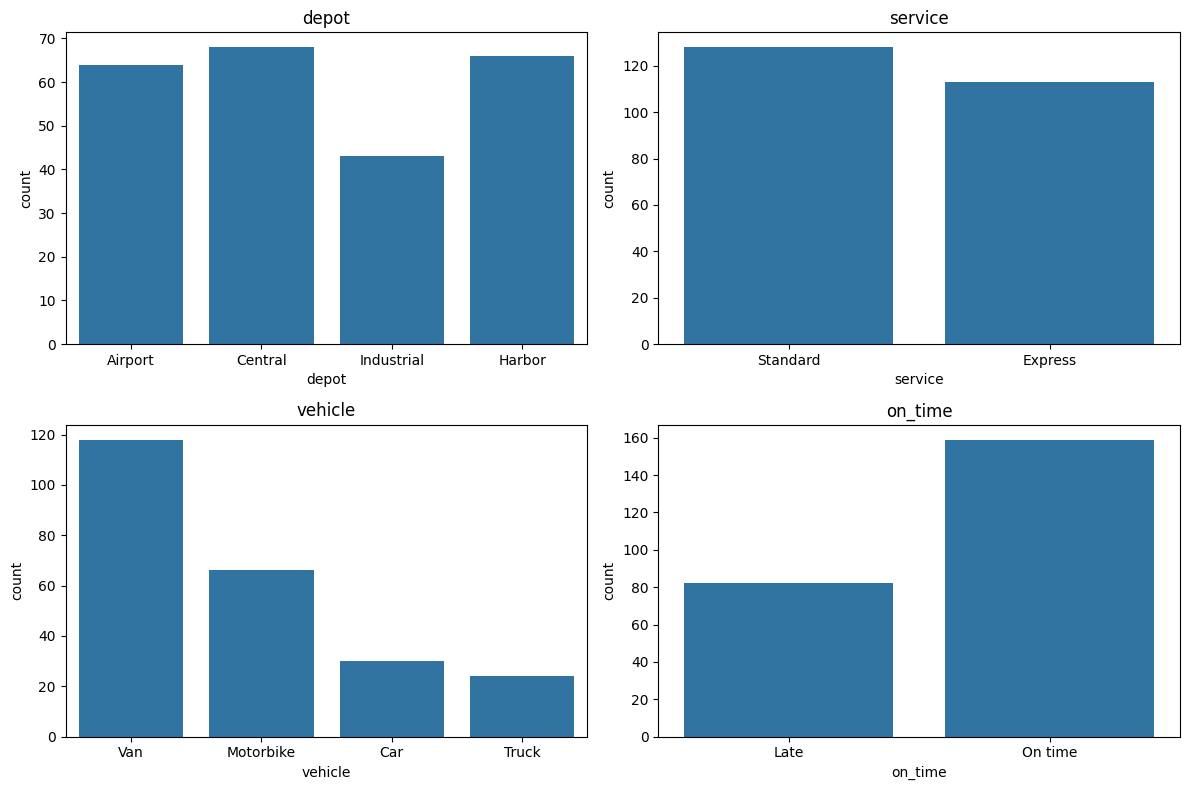

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, column in zip(axes.flatten(), ["depot", "service", "vehicle", "on_time"]):
    sns.countplot(data=df, x=column, ax=ax)
    ax.set_title(column)

plt.tight_layout()
plt.show()

En çok kullanılan araç Van. Truck ve Car daha az. <br>
on_time'da On time daha fazla, Late daha az. <br>

## Numerical distributions

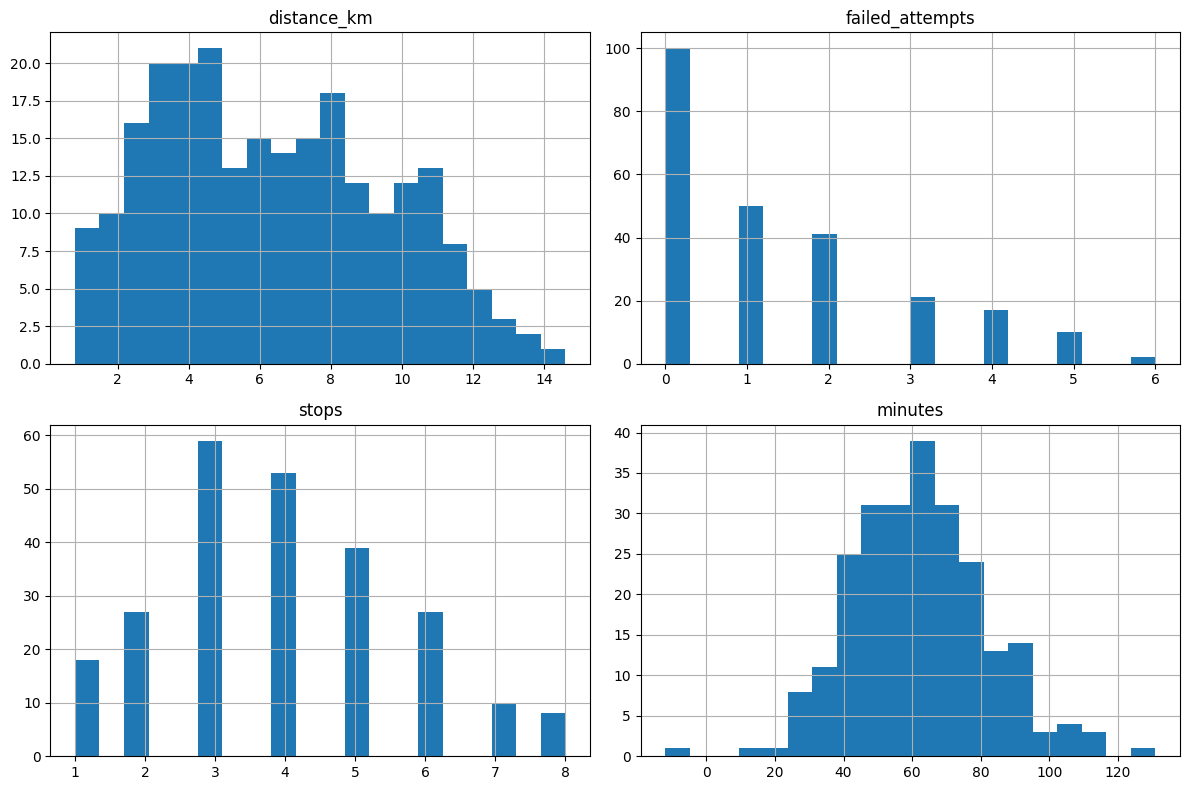

In [12]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

distance_km 0-15 km arasında dağılmış. </br>
failed_attempts çoğunlukla 0-2 arasında. </br>
stops 1-8 arasında. </br>
minutes ise normale yakın dağılmış ama uçlarda aykırı değerler var. </br>

## Outliers

Outlier tespiti

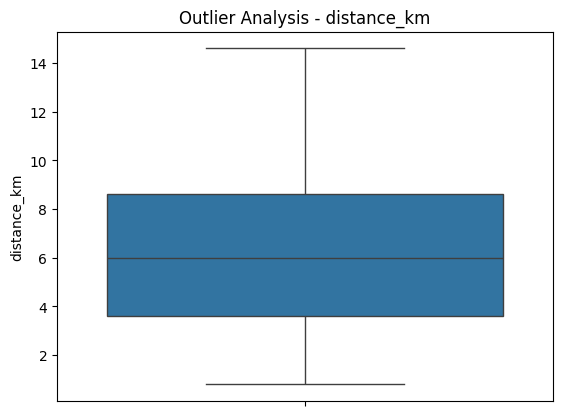

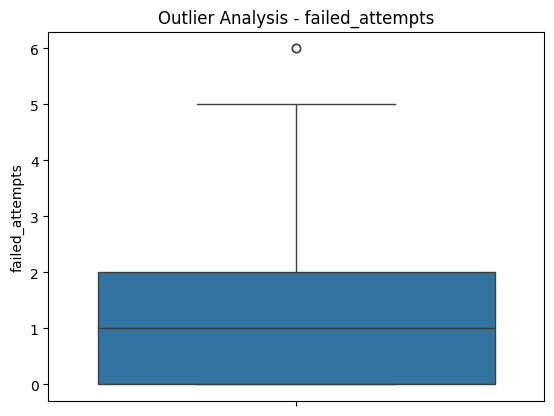

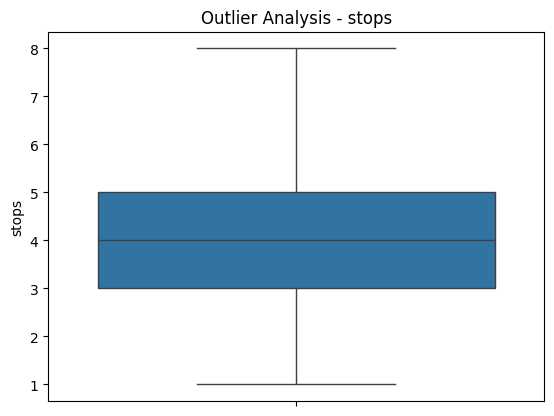

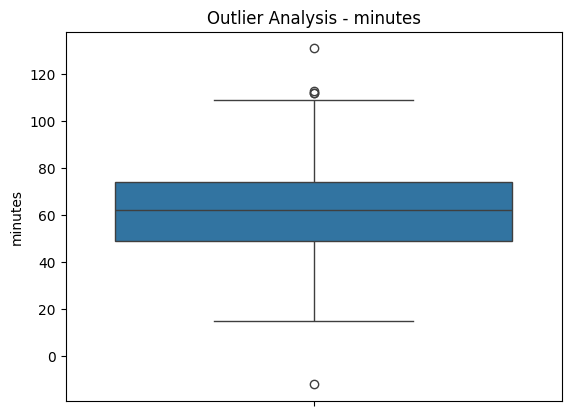

In [13]:
for column in df.select_dtypes(include=np.number).columns:
    sns.boxplot(data=df[column])
    plt.xticks(rotation=45)
    plt.title(f"Outlier Analysis - {column}")
    plt.show()

## Korrelation Matrix

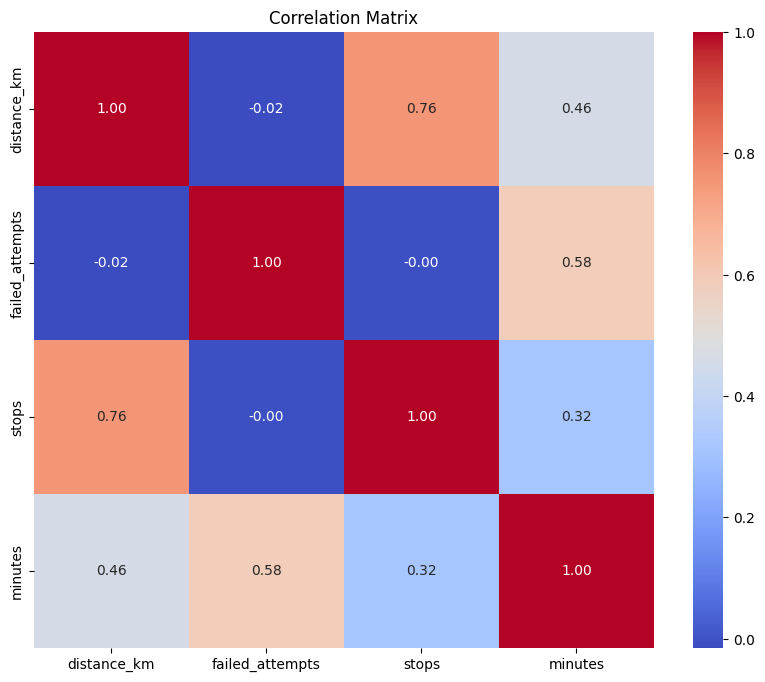

In [14]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

distance_km ve stops arasında yüksek korelasyon var (0.76). Mesafe arttıkça durak sayısı da artıyor. <br>
minutes ile en yüksek korelasyon failed_attempts'te (0.58). Başarısız deneme arttıkça süre uzuyor. <br>

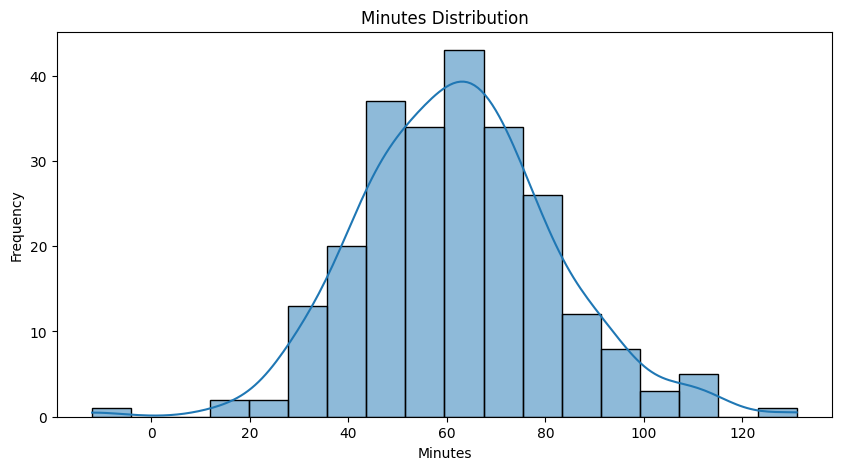

In [15]:
plt.figure(figsize=(10, 5))

sns.histplot(df["minutes"], kde=True)

plt.title("Minutes Distribution")
plt.xlabel("Minutes")
plt.ylabel("Frequency")

plt.show()

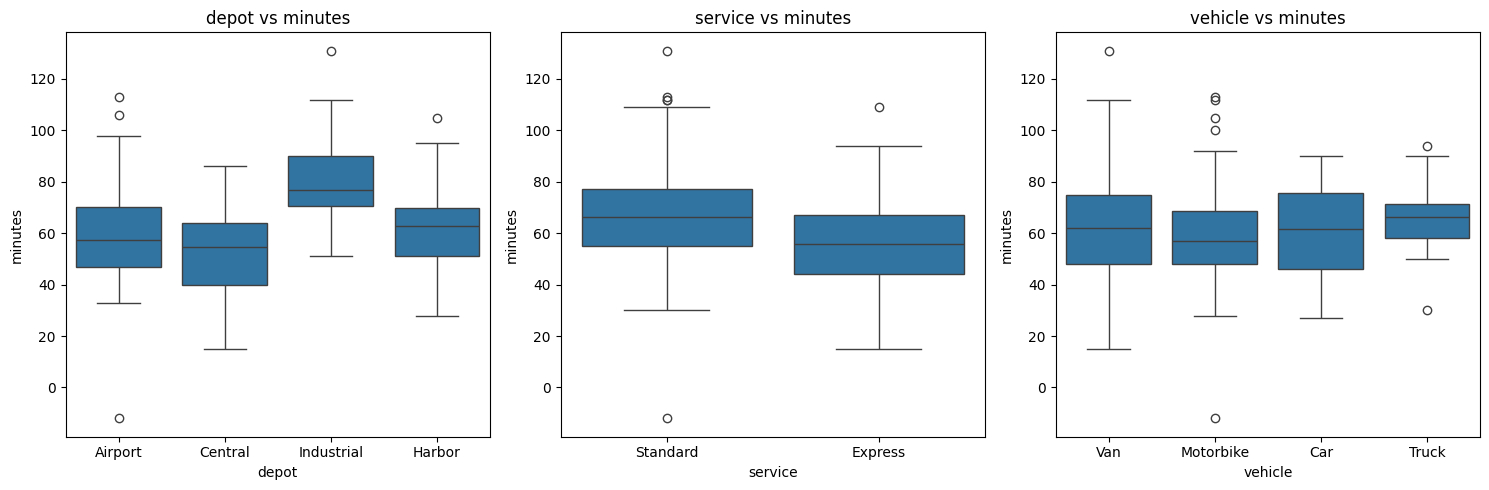

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, column in zip(axes, ["depot", "service", "vehicle"]):
    sns.boxplot(data=df, x=column, y="minutes", ax=ax)
    ax.set_title(f"{column} vs minutes")

plt.tight_layout()
plt.show()

Express teslimatlar Standard'a göre daha kısa sürüyor. <br>

# Data Cleaning

Veri temizleme işlemleri

In [17]:
print(df.dtypes)
df.info()

shipment_id         object
depot               object
service             object
vehicle             object
distance_km        float64
failed_attempts      int64
stops                int64
minutes              int64
on_time             object
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   shipment_id      241 non-null    object 
 1   depot            241 non-null    object 
 2   service          241 non-null    object 
 3   vehicle          238 non-null    object 
 4   distance_km      237 non-null    float64
 5   failed_attempts  241 non-null    int64  
 6   stops            241 non-null    int64  
 7   minutes          241 non-null    int64  
 8   on_time          241 non-null    object 
dtypes: float64(1), int64(3), object(5)
memory usage: 17.1+ KB


## Removing Unnecessary Columns

shipment_id sadece bir id, modele bir katkısı yok. <br>
on_time ise teslimat bittikten sonra belli olan bir bilgi. Süreyi tahmin ederken bunu bilemeyiz, kullanırsak data leakage olur. İkisi de silinmeli. <br>

In [18]:
df = df.drop(columns=["shipment_id", "on_time"])
print(df.columns.tolist())

['depot', 'service', 'vehicle', 'distance_km', 'failed_attempts', 'stops', 'minutes']


## Removing Invalid Minutes

minutes değeri 0 veya negatif olan satırlar hatalı, silinmeli. <br>

In [19]:
print(df[df["minutes"] <= 0])

df = df[df["minutes"] > 0].copy()
print(f"New Dataset Shape: {df.shape}")

      depot   service    vehicle  distance_km  failed_attempts  stops  minutes
37  Airport  Standard  Motorbike         10.1                2      7      -12
New Dataset Shape: (240, 7)


### Normalize Categorical Text

In [20]:
for column in ["depot", "service", "vehicle"]:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
    )

for column in ["depot", "service", "vehicle"]:
    print(column, df[column].unique())

depot <StringArray>
['Airport', 'Central', 'Industrial', 'Harbor']
Length: 4, dtype: string
service <StringArray>
['Standard', 'Express']
Length: 2, dtype: string
vehicle <StringArray>
['Van', 'Motorbike', 'Car', 'Truck', <NA>]
Length: 5, dtype: string


kategorilerde boşluk vs. olmasın diye strip yapıldı. Farklı yazılmış değer yok. <br>

## Duplicate Values

Tekrarlayan satırların tespiti ve silinmesi

In [21]:
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

display(df[df.duplicated(keep=False)])

Duplicate Rows: 1


,depot,service,vehicle,distance_km,failed_attempts,stops,minutes
120,Industrial,Standard,Motorbike,5.9,0,5,64
240,Industrial,Standard,Motorbike,5.9,0,5,64


In [22]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate Rows after removal:", df.duplicated().sum())
print(f"New Dataset Shape: {df.shape}")

Duplicate Rows after removal: 0
New Dataset Shape: (239, 7)


Duplicate ve hatalı satırlar kaldırıldığında geriye 239 örneklem kalıyor. <br>

## Missing Values

Eksik verilerin belirlenmesi

In [23]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
depot,0,0.00
service,0,0.00
vehicle,3,1.26
distance_km,4,1.67
failed_attempts,0,0.00
stops,0,0.00
minutes,0,0.00


vehicle ve distance_km'de az sayıda null var. <br>
Data leakage olmaması için bunlar train/test ayrıldıktan sonra train verisine göre doldurulacak. <br>

# Dataset Splitting

Veri setinin eğitim ve test setlerine ayrılması <br>
Oran 80-20 olacak şekilde ayarlanacak. <br>

In [24]:
X = df.drop(columns=["minutes"])
y = df["minutes"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (191, 6)
Test: (48, 6)


Veriler bölündükten sonra 191 train ve 48 test örneklemi var.

# Preprocessing

Veriyi ön işleme

In [25]:
numeric_features = [
    "distance_km",
    "failed_attempts",
    "stops"
]

nominal_features = [
    "depot",
    "service",
    "vehicle"
]

### Filling Missing Values

In [26]:
print("X_train missing:\n", X_train.isnull().sum())
print("\nX_test missing:\n", X_test.isnull().sum())

X_train missing:
 depot              0
service            0
vehicle            2
distance_km        4
failed_attempts    0
stops              0
dtype: int64

X_test missing:
 depot              0
service            0
vehicle            1
distance_km        0
failed_attempts    0
stops              0
dtype: int64


vehicle kategorik olduğu için en çok görülen değer (mode) ile dolduruldu. <br>
distance_km sayısal olduğu için median ile dolduruldu. Median aykırı değerlerden daha az etkilenir. <br>

In [27]:
mfv_vehicle = X_train["vehicle"].mode()[0]
median_distance = X_train["distance_km"].median()

print("Most common vehicle:", mfv_vehicle)
print("Median distance:", median_distance)

X_train["vehicle"] = X_train["vehicle"].fillna(mfv_vehicle)
X_test["vehicle"] = X_test["vehicle"].fillna(mfv_vehicle)

X_train["distance_km"] = X_train["distance_km"].fillna(median_distance)
X_test["distance_km"] = X_test["distance_km"].fillna(median_distance)

print("X_train empty values:", X_train.isnull().sum().sum())
print("X_test empty values:", X_test.isnull().sum().sum())

Most common vehicle: Van
Median distance: 5.9
X_train empty values: 0
X_test empty values: 0


Train verisinde en çok görülen araç Van çıktı. <br>
Test verisi de train'den hesaplanan değerlerle dolduruldu ki data leakage olmasın. <br>

## Categorical Columns Processing

In [28]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(X_train[column].value_counts(dropna=False))


--- depot ---
depot
Central       53
Airport       52
Harbor        52
Industrial    34
Name: count, dtype: Int64

--- service ---
service
Standard    101
Express      90
Name: count, dtype: Int64

--- vehicle ---
vehicle
Van          96
Motorbike    49
Car          24
Truck        22
Name: count, dtype: Int64


### One-Hot Encoding

depot, service ve vehicle sütunlarında sıralama yok, hepsi nominal kategorik değişken. Bu yüzden üçüne de one-hot encoding uygulanacak. <br>
vehicle için Motorbike < Car < Van < Truck gibi bir sıralama düşünülebilir ama bu süreyle doğrudan ilişkili değil, o yüzden ordinal yapılmadı. <br>

In [29]:
X_train = pd.get_dummies(
    X_train,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=nominal_features,
    drop_first=True,
    dtype=int
)

Train ve test kısmına pd.get_dummies() ile one-hot encoding uygulandı. <br>
drop_first=True ile ilk sütun düşürüldü. <br>

In [30]:
X_train.info()
X_train.head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 191 entries, 138 to 102
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   distance_km        191 non-null    float64
 1   failed_attempts    191 non-null    int64  
 2   stops              191 non-null    int64  
 3   depot_Central      191 non-null    int64  
 4   depot_Harbor       191 non-null    int64  
 5   depot_Industrial   191 non-null    int64  
 6   service_Standard   191 non-null    int64  
 7   vehicle_Motorbike  191 non-null    int64  
 8   vehicle_Truck      191 non-null    int64  
 9   vehicle_Van        191 non-null    int64  
dtypes: float64(1), int64(9)
memory usage: 16.4 KB


,distance_km,failed_attempts,stops,depot_Central,depot_Harbor,depot_Industrial,service_Standard,vehicle_Motorbike,vehicle_Truck,vehicle_Van
138,2.7,0,2,0,0,0,0,0,0,1
60,5.9,0,4,1,0,0,1,0,0,1
207,3.6,3,4,0,0,1,0,0,0,0
165,5.2,4,4,1,0,0,0,0,0,1
206,2.2,0,2,1,0,0,1,0,1,0
192,12.5,0,6,0,1,0,1,1,0,0
223,0.8,0,1,1,0,0,0,0,0,1
159,2.4,2,3,0,1,0,0,0,1,0
115,2.1,0,2,1,0,0,0,0,0,0
148,1.4,0,1,1,0,0,0,0,0,1


encoding yapıldıktan sonra sütun sayısı 10'a çıktı

In [31]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Train columns:", X_train.shape[1])
print("Test columns:", X_test.shape[1])

print(
    "Columns match:",
    X_train.columns.equals(X_test.columns)
)

Train columns: 10
Test columns: 10
Columns match: True


Encodingler sonrası train ve test sütun sayıları eşitlenmesinin kontrol edilmesi

# Outlier Detection

In [32]:
numeric_columns = [
    "distance_km",
    "failed_attempts",
    "stops",
    "minutes"
]

## IQR

In [33]:
outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,distance_km,3.6,8.55,4.95,-3.83,15.98,0,0.00
1,failed_attempts,0.0,2.00,2.00,-3.00,5.00,2,0.84
2,stops,3.0,5.00,2.00,0.00,8.00,0,0.00
3,minutes,49.5,74.00,24.50,12.75,110.75,4,1.67


## Z-Score

In [34]:
for column in numeric_columns:

    z_scores = np.abs(zscore(df[column].dropna()))

    outlier_count = (z_scores > 3).sum()

    print(f"{column}: {outlier_count} outliers")

distance_km: 0 outliers
failed_attempts: 2 outliers
stops: 0 outliers
minutes: 1 outliers


IQR yöntemine göre failed_attempts'te 2, minutes'ta 4 aykırı değer var. Z-Score'a göre ise minutes'ta sadece 1 tane var. <br>
Sayıları çok az ve gerçek teslimatlar olabilir (çok başarısız deneme olunca süre uzuyor). Veri de zaten küçük olduğu için bunlar silinmedi. <br>

# Scaling

verilerin ölçeklenmesi

In [35]:
scaling_columns = [
    "distance_km",
    "failed_attempts",
    "stops"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scaling_columns] = scaler.fit_transform(X_train[scaling_columns])
X_test_scaled[scaling_columns] = scaler.transform(X_test[scaling_columns])

distance_km, failed_attempts ve stops sütunları için StandardScaler kullanıldı. Ortalama 0, standart sapma 1 olacak şekilde ölçeklendi. <br>
Scaler sadece train verisine fit edildi, test verisine sadece transform yapıldı. <br>

In [36]:
X_train_scaled.head(10)

,distance_km,failed_attempts,stops,depot_Central,depot_Harbor,depot_Industrial,service_Standard,vehicle_Motorbike,vehicle_Truck,vehicle_Van
138,-1.104092,-0.913574,-1.133599,0,0,0,0,0,0,1
60,-0.119814,-0.913574,0.062630,1,0,0,1,0,0,1
207,-0.827264,1.084434,0.062630,0,0,1,0,0,0,0
165,-0.335125,1.750436,0.062630,1,0,0,0,0,0,1
206,-1.257886,-0.913574,-1.133599,1,0,0,1,0,1,0
192,1.910260,-0.913574,1.258859,0,1,0,1,1,0,0
223,-1.688508,-0.913574,-1.731714,1,0,0,0,0,0,1
159,-1.196369,0.418431,-0.535485,0,1,0,0,0,1,0
115,-1.288645,-0.913574,-1.133599,1,0,0,0,0,0,0
148,-1.503956,-0.913574,-1.731714,1,0,0,0,0,0,1


# Training Model

Modellerin Eğitilmesi

## Linear Regression

In [37]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:
y_pred = linear_model.predict(X_test_scaled)

In [39]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Results
--------------------------------
MAE  : 5.19
MSE  : 38.22
RMSE : 6.18
R²   : 0.8924


Linear Regression Model Results
--------------------------------
MAE  : 5.19<br>
MSE  : 38.22<br>
RMSE : 6.18<br>
R²   : 0.8924<br><br><br>

Modelin R² değeri 0.8924 çıktı. Yani model teslimat süresindeki değişimin %89.24'ünü açıklayabiliyor. <br><br>
MAE değeri 5.19 çıktı. Yani model tahminlerinde ortalama 5.19 dakika yanılıyor. <br><br>
RMSE değeri 6.18 çıktı. MAE'ye yakın olması büyük hataların çok fazla olmadığını gösterir. <br><br>

En basit model olmasına rağmen performansı oldukça iyi. Demek ki süre ile featurelar arasında büyük ölçüde doğrusal bir ilişki var. <br><br>

In [40]:
coefficients = pd.DataFrame({
    "Feature": X_train_scaled.columns,
    "Coefficient": linear_model.coef_
}).sort_values(by="Coefficient", ascending=False)

display(coefficients)

,Feature,Coefficient
5,depot_Industrial,17.663783
1,failed_attempts,11.869679
0,distance_km,9.111739
8,vehicle_Truck,1.732007
2,stops,0.807581
6,service_Standard,0.395534
9,vehicle_Van,-0.099623
7,vehicle_Motorbike,-1.617511
4,depot_Harbor,-2.352298
3,depot_Central,-12.019005


Katsayılara bakınca süreyi en çok artıran şey Industrial deposundan çıkmak (+17.7 dk). EDA'da da Industrial'ın ortalaması 82 dk ile en yüksekti. <br>
failed_attempts ve distance_km de süreyi ciddi artırıyor. <br>
Central deposu ise süreyi en çok azaltan değişken. <br>
Araç tipinin ve service'in etkisi az çıktı. <br>

In [41]:
comparison = pd.DataFrame({
    "Actual Minutes": y_test,
    "Predicted Minutes": y_pred
})

print(comparison.head(10))

     Actual Minutes  Predicted Minutes
24               39          42.125484
6                63          69.186759
93               89          84.906306
109              48          44.303525
104              46          55.094506
172              43          44.235009
200              59          57.499373
86               67          63.829541
9                67          64.184746
142              50          37.596136


gerçek değerler ile tahmin edilen değerlerin karşılaştırılması

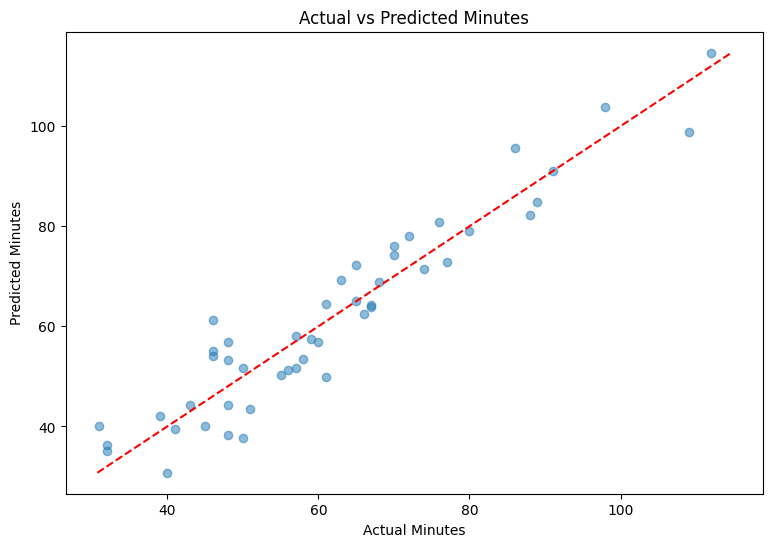

In [42]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Minutes")
plt.ylabel("Predicted Minutes")
plt.title("Actual vs Predicted Minutes")
plt.show()

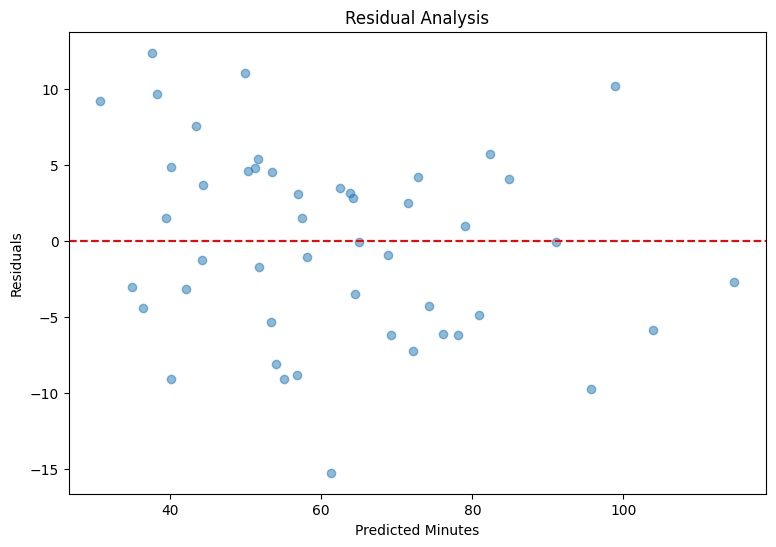

In [43]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Minutes")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

## Random Forest Regressor

Random Forest Modelinin Eğitilmesi

In [44]:
random_forest_model = RandomForestRegressor(n_estimators=100, random_state=42)

random_forest_model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


n_estimators=100 olarak ayarlandı. Bu değer modelin kaç tane karar ağacı oluşturacağını belirler. <br>

In [45]:
y_pred = random_forest_model.predict(X_test_scaled)

In [46]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Random Forest Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Random Forest Regression Model Results
--------------------------------
MAE  : 6.58
MSE  : 62.58
RMSE : 7.91
R²   : 0.8239


Random Forest Regression Model Results
--------------------------------
MAE  : 6.58<br>
MSE  : 62.58<br>
RMSE : 7.91<br>
R²   : 0.8239<br><br><br>

Modelin R² değeri 0.8239 çıktı. Salary verisinin aksine burada Random Forest, Linear Regression'dan daha kötü çıktı. <br><br>
Bunun sebebi veri setinin çok küçük olması (191 train örneklemi) ve ilişkinin zaten doğrusal olması olabilir. Ağaç modelleri doğrusal ilişkiyi basamak basamak öğrenmeye çalıştığı için az veride zorlanıyor. <br><br>

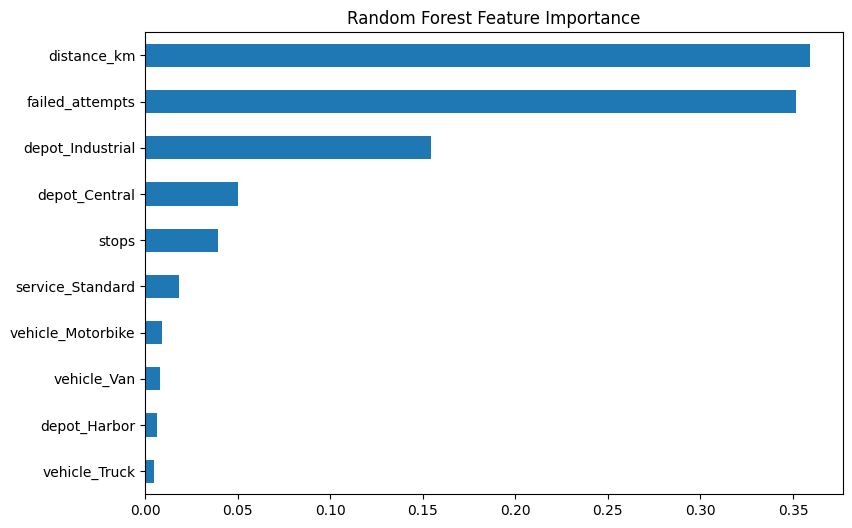

In [47]:
importances = pd.Series(
    random_forest_model.feature_importances_,
    index=X_train_scaled.columns
).sort_values(ascending=False)

importances.plot(kind="barh", figsize=(9, 6))
plt.gca().invert_yaxis()
plt.title("Random Forest Feature Importance")
plt.show()

Random Forest'a göre en önemli featurelar distance_km ve failed_attempts. Sonra depot_Industrial geliyor. <br>
Linear Regression katsayılarıyla benzer bir sonuç çıktı. vehicle sütunlarının önemi çok düşük. <br>

In [48]:
comparison = pd.DataFrame({
    "Actual Minutes": y_test,
    "Predicted Minutes": y_pred
})

print(comparison.head(10))

     Actual Minutes  Predicted Minutes
24               39              36.53
6                63              72.74
93               89              90.74
109              48              39.38
104              46              57.74
172              43              43.33
200              59              60.75
86               67              60.93
9                67              65.15
142              50              41.03


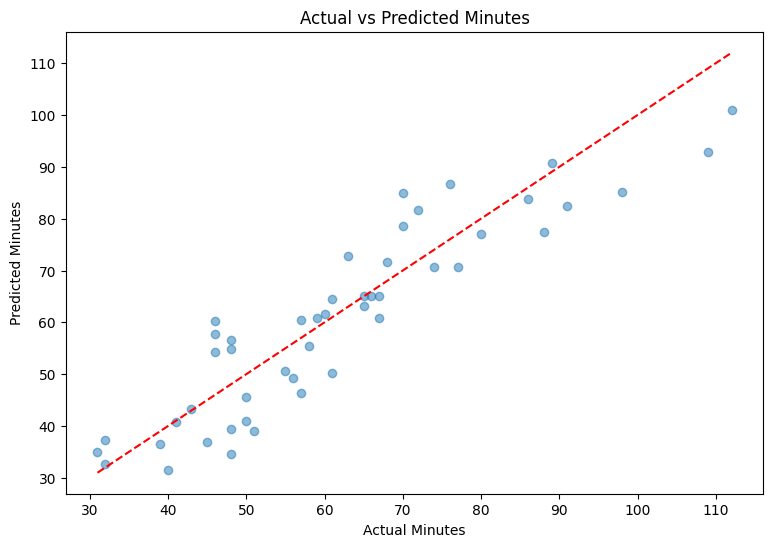

In [49]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Minutes")
plt.ylabel("Predicted Minutes")
plt.title("Actual vs Predicted Minutes")
plt.show()

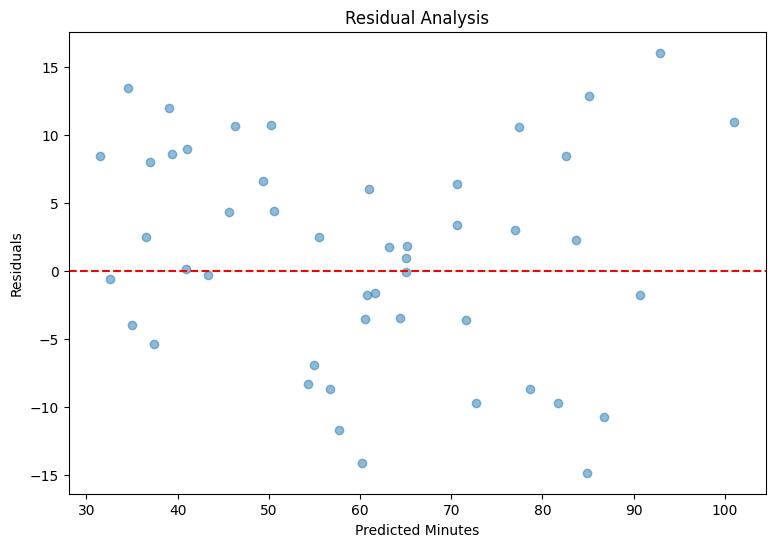

In [50]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Minutes")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

## CatBoost Regressor

CatBoost Modelinin Eğitilmesi

Bu modelde veriler kategorik olarak verildiği için CatBoost'un kendi kategorik işleme algoritması kullanıldı. <br>
One-hot encoding ve scaling adımları atlanarak model eğitildi. <br>

Veri seti küçük olduğu için (239 satır) iterasyon sayısı 1000 olarak ayarlandı. <br>
learning_rate=0.03 ve depth=4 seçildi. Az veride derin ağaçlar kolayca overfit oluyor. <br>

In [51]:
cat_features_list = ["depot", "service", "vehicle"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.columns.tolist())

X_train = X_train.copy()
X_test = X_test.copy()

X_train["distance_km"] = X_train["distance_km"].fillna(median_distance)
X_test["distance_km"] = X_test["distance_km"].fillna(median_distance)

for column in cat_features_list:
    X_train[column] = (
        X_train[column]
        .astype("object")
        .where(X_train[column].notna(), "__missing__")
        .astype(str)
    )
    X_test[column] = (
        X_test[column]
        .astype("object")
        .where(X_test[column].notna(), "__missing__")
        .astype(str)
    )

model = CatBoostRegressor(
    iterations=1000,
    learning_rate=0.03,
    depth=4,
    cat_features=cat_features_list,
    random_seed=42,
    verbose=100
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"\n CatBoost Model Performance:")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

['depot', 'service', 'vehicle', 'distance_km', 'failed_attempts', 'stops']
0:	learn: 18.9684131	total: 58.9ms	remaining: 58.9s
100:	learn: 8.6413483	total: 93.4ms	remaining: 832ms
200:	learn: 6.8841123	total: 116ms	remaining: 462ms
300:	learn: 6.1924147	total: 139ms	remaining: 322ms
400:	learn: 5.7856242	total: 160ms	remaining: 238ms
500:	learn: 5.5248138	total: 185ms	remaining: 184ms
600:	learn: 5.2520607	total: 208ms	remaining: 138ms
700:	learn: 5.0138471	total: 229ms	remaining: 97.6ms
800:	learn: 4.7866336	total: 251ms	remaining: 62.3ms
900:	learn: 4.5798071	total: 271ms	remaining: 29.8ms
999:	learn: 4.3427572	total: 297ms	remaining: 0us

 CatBoost Model Performance:
MAE  : 6.21
MSE  : 60.07
RMSE : 7.75
R²   : 0.8309


CatBoost Model Performance:
--------------------------------
MAE  : 6.21<br>
MSE  : 60.07<br>
RMSE : 7.75<br>
R²   : 0.8309<br><br><br>

Modelin R² değeri 0.8309 çıktı. Random Forest'tan biraz daha iyi ama Linear Regression'ı geçemedi. <br><br>
Salary verisinde CatBoost açık ara en iyisiydi ama burada veri az ve ilişki basit olduğu için boosting'in avantajı ortaya çıkmadı. <br><br>

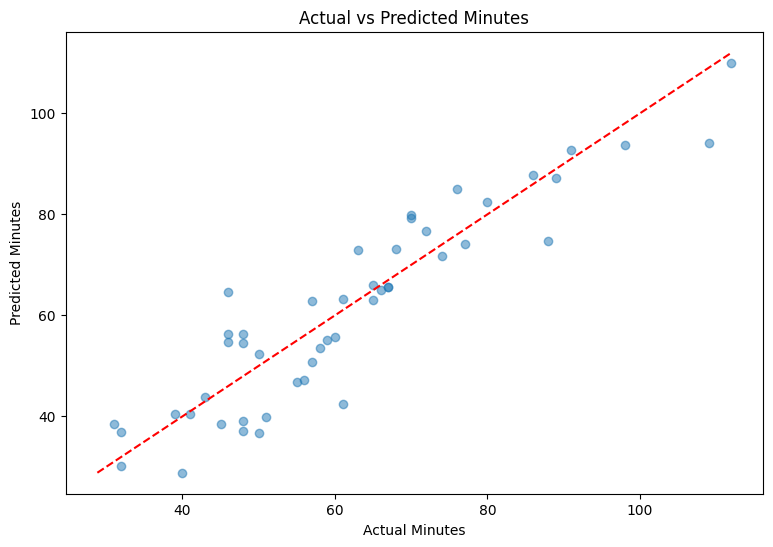

In [52]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Minutes")
plt.ylabel("Predicted Minutes")
plt.title("Actual vs Predicted Minutes")
plt.show()

In [53]:
catboost_results = {"MAE": mae, "RMSE": rmse, "R2": r2}

CatBoost sonuçları en sondaki karşılaştırma için kaydedildi. <br>

## Other Models

Diğer modellerin eğitilmesi <br>
Her model için aynı metrikleri hesaplamak adına küçük bir fonksiyon yazıldı. <br>
Bu modeller one-hot encoding ve scaling yapılmış veriyi (X_train_scaled) kullanıyor. <br>

In [54]:
def evaluate_model(name, model):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    print(f"{name} Model Results")
    print("--------------------------------")
    print(f"MAE  : {mae:.2f}")
    print(f"MSE  : {mse:.2f}")
    print(f"RMSE : {rmse:.2f}")
    print(f"R²   : {r2:.4f}")

    return {"MAE": mae, "RMSE": rmse, "R2": r2}

## Ridge Regression

Ridge, Linear Regression'ın L2 regularization eklenmiş hali. Katsayıları küçültüp overfit'i azaltmaya çalışır. <br>
alpha=1.0 regularization'ın gücünü belirler. <br>

In [55]:
ridge_results = evaluate_model("Ridge", Ridge(alpha=1.0))

Ridge Model Results
--------------------------------
MAE  : 5.20
MSE  : 38.26
RMSE : 6.19
R²   : 0.8923


R² değeri 0.8923 çıktı. Linear Regression ile neredeyse aynı (0.8924). <br>
Model zaten overfit olmadığı için regularization pek bir şey değiştirmedi. <br>

## Lasso Regression

Lasso ise L1 regularization kullanıyor. Önemsiz featureların katsayısını tamamen 0 yapabilir, yani bir çeşit feature seçimi yapıyor. <br>

In [56]:
lasso_model = Lasso(alpha=0.1)
lasso_results = evaluate_model("Lasso", lasso_model)

print("\nKatsayısı 0 olan featurelar:")
print(X_train_scaled.columns[lasso_model.coef_ == 0].tolist())

Lasso Model Results
--------------------------------
MAE  : 5.10
MSE  : 36.77
RMSE : 6.06
R²   : 0.8965

Katsayısı 0 olan featurelar:
['service_Standard', 'vehicle_Van']


R² değeri 0.8965 çıktı. Linear Regression'dan biraz daha iyi. MAE de 5.10'a düştü. <br>
Lasso service_Standard ve vehicle_Van katsayılarını 0 yaptı. Yani bu featurelar süreyi tahmin etmede işe yaramıyor. <br>
Linear Regression katsayılarında da bunların etkisi çok küçük çıkmıştı. <br>

## Decision Tree Regressor

Tek bir karar ağacı. Random Forest'ın tek ağaçlı hali gibi düşünülebilir. <br>
max_depth=5 ile ağacın çok derinleşip overfit olması engellendi. <br>

In [57]:
dt_results = evaluate_model("Decision Tree", DecisionTreeRegressor(max_depth=5, random_state=42))

Decision Tree Model Results
--------------------------------
MAE  : 8.29
MSE  : 108.31
RMSE : 10.41
R²   : 0.6951


R² değeri 0.6951 çıktı. Şimdiye kadarki en kötü sonuç. <br>
Tek bir ağaç veriyi çok kaba parçalara bölüyor. Random Forest'ın bir sürü ağacın ortalamasını alması bu yüzden daha iyi çalışıyor. <br>

## KNN Regressor

KNN, test örneğine en yakın k tane train örneğinin ortalamasını tahmin olarak veriyor. <br>
Mesafe hesapladığı için scaling yapılmış veri kullanmak önemli. <br>

In [58]:
for k in [3, 5, 7, 9, 11]:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    print(f"k={k}  R²: {r2_score(y_test, model.predict(X_test_scaled)):.4f}")

k=3  R²: 0.7457
k=5  R²: 0.7861
k=7  R²: 0.7928
k=9  R²: 0.7755
k=11  R²: 0.7807


Farklı k değerleri denendi. En iyi sonuç k=7'de çıktı. <br>
Normalde k'yı test verisine bakarak değil cross-validation ile seçmek daha doğru, burada basit tutuldu. <br>

In [59]:
knn_results = evaluate_model("KNN", KNeighborsRegressor(n_neighbors=7))

KNN Model Results
--------------------------------
MAE  : 6.71
MSE  : 73.59
RMSE : 8.58
R²   : 0.7928


R² değeri 0.7928 çıktı. Linear modellerin gerisinde kaldı. <br>
One-hot sütunlar 0-1, scale edilen sütunlar ise -2 ile 2 arasında olduğu için mesafe hesabında bazı featurelar daha baskın olabiliyor. <br>

## SVR

Support Vector Regression. kernel="rbf" ile doğrusal olmayan ilişkileri de yakalayabiliyor. <br>
C değeri hataya ne kadar ceza verileceğini belirler. Hedef değişken dakika cinsinden olduğu için C yüksek tutuldu. <br>

In [60]:
svr_results = evaluate_model("SVR", SVR(kernel="rbf", C=100, epsilon=1))

SVR Model Results
--------------------------------
MAE  : 6.65
MSE  : 66.28
RMSE : 8.14
R²   : 0.8134


R² değeri 0.8134 çıktı. Random Forest'a yakın bir sonuç. <br>
rbf kernel doğrusal olmayan ilişki aradığı için doğrusal bir veride Linear Regression'ı geçemedi. <br>

## Gradient Boosting Regressor

sklearn'ün kendi boosting modeli. CatBoost gibi ağaçları sırayla ekleyip bir öncekinin hatasını düzeltmeye çalışıyor. <br>
Veri az olduğu için max_depth=3 ve learning_rate=0.05 seçildi. <br>

In [61]:
gb_results = evaluate_model(
    "Gradient Boosting",
    GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
)

Gradient Boosting Model Results
--------------------------------
MAE  : 6.67
MSE  : 69.68
RMSE : 8.35
R²   : 0.8038


R² değeri 0.8038 çıktı. CatBoost'tan biraz daha kötü. <br>
CatBoost kategorik verileri kendisi işlediği için burada biraz avantajlı. <br>

# Results

Modellerin karşılaştırılması

In [62]:
lr_metrics = {
    "MAE": mean_absolute_error(y_test, linear_model.predict(X_test_scaled)),
    "RMSE": np.sqrt(mean_squared_error(y_test, linear_model.predict(X_test_scaled))),
    "R2": r2_score(y_test, linear_model.predict(X_test_scaled))
}

rf_metrics = {
    "MAE": mean_absolute_error(y_test, random_forest_model.predict(X_test_scaled)),
    "RMSE": np.sqrt(mean_squared_error(y_test, random_forest_model.predict(X_test_scaled))),
    "R2": r2_score(y_test, random_forest_model.predict(X_test_scaled))
}

results = pd.DataFrame({
    "Linear Regression": lr_metrics,
    "Ridge": ridge_results,
    "Lasso": lasso_results,
    "Decision Tree": dt_results,
    "KNN": knn_results,
    "SVR": svr_results,
    "Random Forest": rf_metrics,
    "Gradient Boosting": gb_results,
    "CatBoost": catboost_results
}).T.sort_values(by="R2", ascending=False)

display(results.round(4))

,MAE,RMSE,R2
Lasso,5.0999,6.0640,0.8965
Linear Regression,5.1854,6.1819,0.8924
Ridge,5.1974,6.1858,0.8923
CatBoost,6.2106,7.7504,0.8309
Random Forest,6.5810,7.9106,0.8239
SVR,6.6527,8.1415,0.8134
Gradient Boosting,6.6722,8.3477,0.8038
KNN,6.7054,8.5787,0.7928
Decision Tree,8.2941,10.4073,0.6951


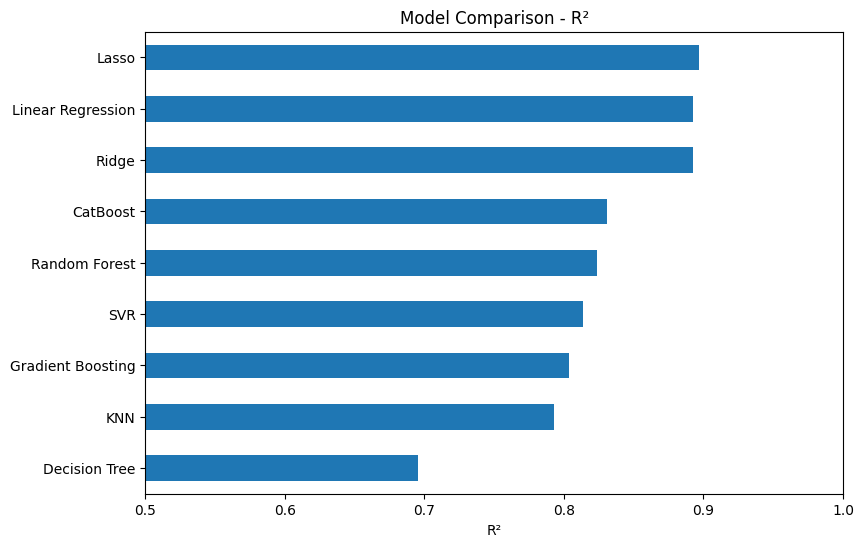

In [63]:
results["R2"].sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Model Comparison - R²")
plt.xlabel("R²")
plt.xlim(0.5, 1)
plt.show()

Sonuçlar R²'ye göre büyükten küçüğe sıralandı. <br><br>

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Lasso | 5.10 | 6.06 | 0.8965 |
| Linear Regression | 5.19 | 6.18 | 0.8924 |
| Ridge | 5.20 | 6.19 | 0.8923 |
| CatBoost | 6.21 | 7.75 | 0.8309 |
| Random Forest | 6.58 | 7.91 | 0.8239 |
| SVR | 6.65 | 8.14 | 0.8134 |
| Gradient Boosting | 6.67 | 8.35 | 0.8038 |
| KNN | 6.71 | 8.58 | 0.7928 |
| Decision Tree | 8.29 | 10.41 | 0.6951 |

<br>
En iyi sonucu Lasso verdi, ama ilk 3 model (Lasso, Linear Regression, Ridge) neredeyse aynı. Üçü de doğrusal model. <br>
Teslimat süresi büyük ölçüde mesafe, başarısız deneme sayısı ve depoya göre doğrusal olarak değişiyor. <br>
Ağaç tabanlı modeller (CatBoost, Random Forest, Gradient Boosting) ortada kaldı, tek Decision Tree ise en kötüsü oldu. <br>
Veri seti küçük olduğu için (191 train) karmaşık modeller daha iyi sonuç vermedi. Daha fazla veri olsaydı ağaç modellerinin performansı artabilirdi. <br>
Ayrıca test seti sadece 48 örneklem, o yüzden modeller arasındaki küçük farklar şans eseri de olabilir. <br>